# code_100 · Entity factors and new-building transfer

**Book:** section 20.3. A self-contained representation laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_20_GUIDE.md), [run evidence](../CHAPTER_20_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_100).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2100;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2100


<a id="entities"></a>
 ## A row lookup cannot invent an unseen entity
 Generate 50 buildings and eight member types from a rank-two response mechanism plus noise. Only four cells per each of 36 training buildings are observed. Seven entire development buildings select the descriptor-map ridge penalty; seven final buildings remain locked. Warm missing-cell assessment and cold-building assessment answer different questions. The matrix factors use response labels, so this is supervised latent fitting, not unlabeled pretraining. A separate known-node cycle example exposes graph embedding identity contracts.


,alpha,development_MSE
0,0.1,0.046977
1,1.0,0.051172
2,10.0,0.128256


Warm / cold fallback / cold mapped MSE: 0.028886502376827747 0.9009941852417638 0.04986697027046933


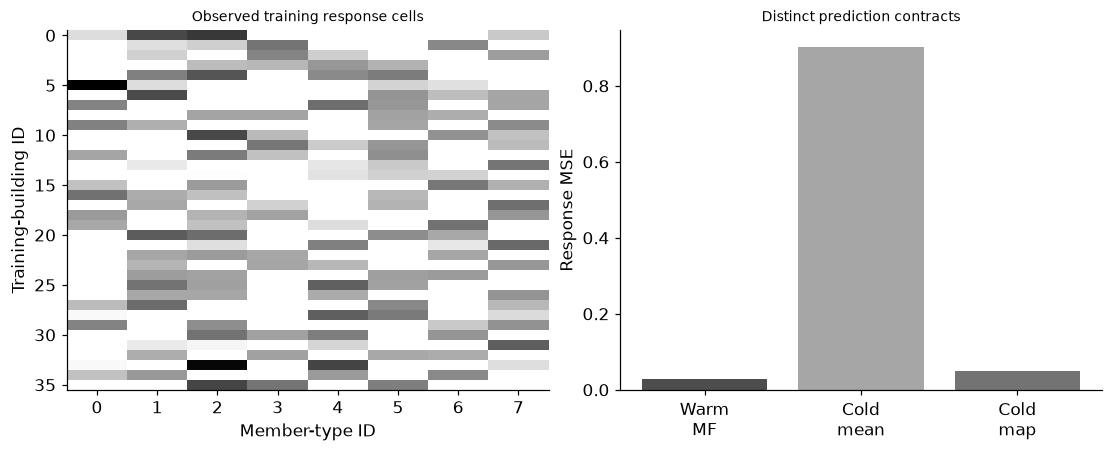

In [2]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
descriptors=rng.normal(size=(50,3));mapping=np.array([[1.,.2],[-.3,.8],[.6,-.4]])
true_u=descriptors@mapping+rng.normal(0,.15,(50,2));true_v=rng.normal(size=(8,2));response=3+true_u@true_v.T+rng.normal(0,.1,(50,8))
mask=np.zeros((36,8),bool)
for i in range(36):mask[i,rng.choice(8,4,replace=False)]=True
assert mask.sum()==144 and np.all(mask.sum(0)>0)
observed=response[:36];u=rng.normal(0,.1,(36,2));v=rng.normal(0,.1,(8,2));mu=float(observed[mask].mean());penalty=.1;history=[]
def objective():return float(np.sum((observed-mu-u@v.T)[mask]**2)+penalty*(np.sum(u*u)+np.sum(v*v)))
history.append(objective())
for iteration in range(80):
    for i in range(36):
        a=v[mask[i]];u[i]=np.linalg.solve(a.T@a+penalty*np.eye(2),a.T@(observed[i,mask[i]]-mu))
    for j in range(8):
        a=u[mask[:,j]];v[j]=np.linalg.solve(a.T@a+penalty*np.eye(2),a.T@(observed[mask[:,j],j]-mu))
    mu=float((observed-u@v.T)[mask].mean());history.append(objective())
assert np.max(np.diff(history))<1e-8
warm=mu+u@v.T;scale=StandardScaler().fit(descriptors[:36]);candidates=[];mappers={}
for alpha in [.1,1.,10.]:
    model=Ridge(alpha=alpha).fit(scale.transform(descriptors[:36]),u);mappers[alpha]=model
    prediction=mu+model.predict(scale.transform(descriptors[36:43]))@v.T
    candidates.append({'alpha':alpha,'development_MSE':float(np.mean((prediction-response[36:43])**2))})
selected=min(candidates,key=lambda r:r['development_MSE'])['alpha'];prediction=mu+mappers[selected].predict(scale.transform(descriptors[43:]))@v.T
warm_mse=float(np.mean((warm-observed)[~mask]**2));cold_baseline=float(np.mean((mu-response[43:])**2));cold_mse=float(np.mean((prediction-response[43:])**2))
assert set(range(36)).isdisjoint(range(43,50)) and prediction.shape==(7,8)
RESULTS.update(observed_cells=int(mask.sum()),warm_missing_cells=int((~mask).sum()),development=candidates,selected_alpha=selected,warm_missing_MSE=warm_mse,cold_ID_fallback_MSE=cold_baseline,cold_descriptor_MSE=cold_mse,objective_initial=history[0],objective_final=history[-1],split_buildings=[36,7,7])
display(pd.DataFrame(candidates));print('Warm / cold fallback / cold mapped MSE:',warm_mse,cold_baseline,cold_mse)
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].imshow(np.where(mask,observed,np.nan),aspect='auto',cmap='Greys');axes[0].set(title='Observed training response cells',xlabel='Member-type ID',ylabel='Training-building ID')
axes[1].bar(range(3),[warm_mse,cold_baseline,cold_mse],color=['.3','.65','.45']);axes[1].set(xticks=range(3),xticklabels=['Warm\nMF','Cold\nmean','Cold\nmap'],ylabel='Response MSE',title='Distinct prediction contracts');plt.show()


<a id="graph-contract"></a>
 ## Graph coordinates identify a relation, not a universal axis
 Use the first two nonconstant eigenvectors of the combinatorial Laplacian of a twelve-node cycle. All nodes and edges are known during embedding. Orthogonal rotation changes coordinates while preserving pairwise distances and inner products. A thirteenth unseen node has no fitted lookup row. The descriptor mapper above supplies an explicit inductive contract for buildings; it does not turn the graph lookup into an inductive method. Factor rotation similarly prevents reading one coordinate as stiffness without further identification.


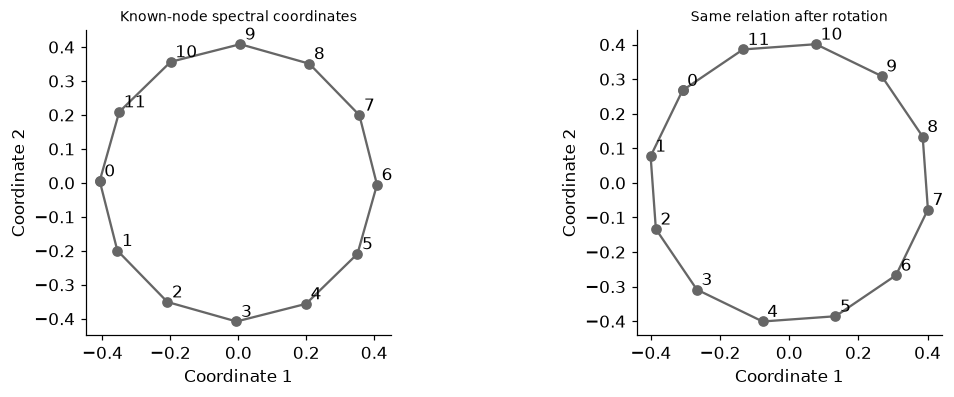

In [3]:
adjacency=np.zeros((12,12))
for i in range(12):adjacency[i,(i+1)%12]=adjacency[(i+1)%12,i]=1
eigenvalues,eigenvectors=np.linalg.eigh(np.diag(adjacency.sum(1))-adjacency);embedding=eigenvectors[:,1:3]
theta=.7;rotation=np.array([[np.cos(theta),-np.sin(theta)],[np.sin(theta),np.cos(theta)]])
np.testing.assert_allclose(embedding@embedding.T,(embedding@rotation)@(embedding@rotation).T,atol=1e-12)
assert embedding.shape==(12,2) and 12 not in range(len(embedding))
RESULTS.update(graph_nodes=12,graph_eigenvalues=eigenvalues[:4].tolist(),rotation_gram_max_error=float(np.max(np.abs(embedding@embedding.T-(embedding@rotation)@(embedding@rotation).T))))
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
for ax,z,title in zip(axes,[embedding,embedding@rotation],['Known-node spectral coordinates','Same relation after rotation']):
    closed=np.vstack([z,z[0]]);ax.plot(closed[:,0],closed[:,1],'o-',color='.4')
    for i,point in enumerate(z):ax.annotate(str(i),point,xytext=(3,3),textcoords='offset points')
    ax.set(title=title,xlabel='Coordinate 1',ylabel='Coordinate 2',aspect='equal')
plt.show()


In [4]:
summary={'example_id':'code_100','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['masked matrix factorization', 'whole-entity holdout', 'inductive descriptor mapping', 'transductive graph coordinates'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["masked matrix factorization", "whole-entity holdout", "inductive descriptor mapping", "transductive graph coordinates"], "elapsed_seconds": 0.293, "example_id": "code_100", "hardware": "Darwin arm64 CPU", "results": {"cold_ID_fallback_MSE": 0.9009941852417638, "cold_descriptor_MSE": 0.04986697027046933, "development": [{"alpha": 0.1, "development_MSE": 0.046977415284414105}, {"alpha": 1.0, "development_MSE": 0.05117193173785776}, {"alpha": 10.0, "development_MSE": 0.12825581795720656}], "graph_eigenvalues": [5.5511151231255886e-17, 0.26794919243112214, 0.26794919243112225, 0.9999999999999996], "graph_nodes": 12, "objective_final": 5.279290273783243, "objective_initial": 150.16336120882713, "observed_cells": 144, "rotation_gram_max_error": 5.551115123125783e-17, "selected_alpha": 0.1, "split_buildings": [36, 7, 7], "warm_missing_MSE": 0.028886502376827747, "warm_missing_cells": 144}, "seed": 2100, "versions": {"matplotlib": "3.11.0", "n